In [8]:
import pandas as pd

# 1. Keep all columns on a single line with a scrollbar
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 1000)

# 2. Load using the correct relative path from your current folder
df = pd.read_csv('Analysing-pharmaceutical-sales-data/data/salesdaily.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [9]:
df

,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour,Weekday Name
0,1/2/2014,0.00,3.670,3.40,32.40,7.0,0.0,0.0,2.00,2014,1,248,Thursday
1,1/3/2014,8.00,4.000,4.40,50.60,16.0,0.0,20.0,4.00,2014,1,276,Friday
2,1/4/2014,2.00,1.000,6.50,61.85,10.0,0.0,9.0,1.00,2014,1,276,Saturday
3,1/5/2014,4.00,3.000,7.00,41.10,8.0,0.0,3.0,0.00,2014,1,276,Sunday
4,1/6/2014,5.00,1.000,4.50,21.70,16.0,2.0,6.0,2.00,2014,1,276,Monday
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2101,10/4/2019,7.34,5.683,2.25,22.45,13.0,0.0,1.0,1.00,2019,10,276,Friday
2102,10/5/2019,3.84,5.010,6.00,25.40,7.0,0.0,0.0,0.33,2019,10,276,Saturday
2103,10/6/2019,4.00,11.690,2.00,34.60,6.0,0.0,5.0,4.20,2019,10,276,Sunday
2104,10/7/2019,7.34,4.507,3.00,50.80,6.0,0.0,10.0,1.00,2019,10,276,Monday


In [11]:
# Question 1: Total sales quantities for each drug category (ATC code)
drug_categories = ['M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03', 'R06']

# 1. Calculate the total sum
total_sales = df[drug_categories].sum()

# 2. Format with commas and 2 decimal places
formatted_sales = total_sales.map('{:,.2f}'.format)

# 3. Print the clean results
print("--- Total Sales Quantities per Drug Category ---")
print(formatted_sales)

--- Total Sales Quantities per Drug Category ---
M01AB    10,600.94
M01AE     8,204.62
N02BA     8,172.21
N02BE    63,005.40
N05B     18,645.74
N05C      1,249.96
R03      11,608.82
R06       6,107.82
dtype: object


In [12]:
# Question 2: Which individual drug categories/brands have the highest total sales?

# 1. Sort the total sales in descending order (highest to lowest)
ranked_sales = total_sales.sort_values(ascending=False)

# 2. Format with commas and 2 decimal places
formatted_ranked_sales = ranked_sales.map('{:,.2f}'.format)

# 3. Print the ranked results
print("--- Ranked Drug Categories by Total Sales (Highest to Lowest) ---")
print(formatted_ranked_sales)

--- Ranked Drug Categories by Total Sales (Highest to Lowest) ---
N02BE    63,005.40
N05B     18,645.74
R03      11,608.82
M01AB    10,600.94
M01AE     8,204.62
N02BA     8,172.21
R06       6,107.82
N05C      1,249.96
dtype: object


In [13]:
# Question 3: Top 3 drug categories for specific months (Jan 2015, Jul 2016, Sep 2017)

# 1. Ensure the date column is properly recognized as datetime
df['datum'] = pd.to_datetime(df['datum'])

drug_categories = ['M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03', 'R06']

# Helper function to filter, sum, and find the top 3 for any given month/year
def get_top_3_sales(year, month, month_name):
    # Filter rows for the target year and month
    filtered_data = df[(df['datum'].dt.year == year) & (df['datum'].dt.month == month)]
    
    # Sum the sales across categories for that period
    sales_sum = filtered_data[drug_categories].sum()
    
    # Sort descending and get the top 3
    top_3 = sales_sum.sort_values(ascending=False).head(3)
    
    # Print clean formatted results
    print(f"--- Top 3 Drug Categories in {month_name} {year} ---")
    print(top_3.map('{:,.2f}'.format))
    print("\n")

# 2. Run the function for our three target dates
get_top_3_sales(2015, 1, "January")
get_top_3_sales(2016, 7, "July")
get_top_3_sales(2017, 9, "September")

--- Top 3 Drug Categories in January 2015 ---
N02BE    1,044.24
N05B       463.00
R03        177.25
dtype: object


--- Top 3 Drug Categories in July 2016 ---
N02BE    652.36
N05B     240.00
M01AB    194.53
dtype: object


--- Top 3 Drug Categories in September 2017 ---
N02BE    863.75
N05B     223.00
R03      139.00
dtype: object




In [15]:
# Question 4: Which drug category sold the most overall in 2017?

# 1. Filter the dataset for the year 2017
df_2017 = df[df['datum'].dt.year == 2017]

# 2. Define our drug categories list
drug_categories = ['M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03', 'R06']

# 3. Sum the sales for each category in 2017 and sort from highest to lowest
sales_2017 = df_2017[drug_categories].sum().sort_values(ascending=False)

# 4. Format numbers cleanly
formatted_sales_2017 = sales_2017.map('{:,.2f}'.format)

# 5. Display the output
print("--- Ranked Drug Category Sales in 2017 ---")
print(formatted_sales_2017)

--- Ranked Drug Category Sales in 2017 ---
N02BE    9,258.80
N05B     2,555.54
R03      1,893.61
M01AB    1,846.62
M01AE    1,387.30
N02BA    1,288.30
R06        988.86
N05C       180.33
dtype: object


In [16]:
# Question 5: Which drug category has the highest average daily sales?

drug_categories = ['M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03', 'R06']

# 1. Calculate the mean (average) for each drug category column and sort descending
average_daily_sales = df[drug_categories].mean().sort_values(ascending=False)

# 2. Format with commas and 2 decimal places
formatted_avg_sales = average_daily_sales.map('{:,.2f}'.format)

# 3. Print the ranked results
print("--- Average Daily Sales per Drug Category (Highest to Lowest) ---")
print(formatted_avg_sales)

--- Average Daily Sales per Drug Category (Highest to Lowest) ---
N02BE    29.92
N05B      8.85
R03       5.51
M01AB     5.03
M01AE     3.90
N02BA     3.88
R06       2.90
N05C      0.59
dtype: object


In [17]:
# Question 6: Are respiratory drugs (R03) sold more during specific months?

# 1. Extract the month name/number and group by month
r03_monthly_sales = df.groupby(df['datum'].dt.month)['R03'].sum()

# 2. Map month numbers (1-12) to month names for readability
month_names = {
    1: 'January', 2: 'February', 3: 'March', 4: 'April',
    5: 'May', 6: 'June', 7: 'July', 8: 'August',
    9: 'September', 10: 'October', 11: 'November', 12: 'December'
}
r03_monthly_sales.index = r03_monthly_sales.index.map(month_names)

# 3. Sort by sales in descending order to easily see peak months
ranked_r03_months = r03_monthly_sales.sort_values(ascending=False)

# 4. Format numbers cleanly
formatted_r03_months = ranked_r03_months.map('{:,.2f}'.format)

# 5. Display the monthly ranking
print("--- Total R03 (Respiratory) Sales by Month (Highest to Lowest) ---")
print(formatted_r03_months)

--- Total R03 (Respiratory) Sales by Month (Highest to Lowest) ---
datum
January      1,264.66
December     1,227.00
October      1,175.00
March        1,170.00
February     1,165.58
April        1,038.88
November       934.00
May            931.29
September      792.42
June           783.00
August         577.00
July           550.00
Name: R03, dtype: object


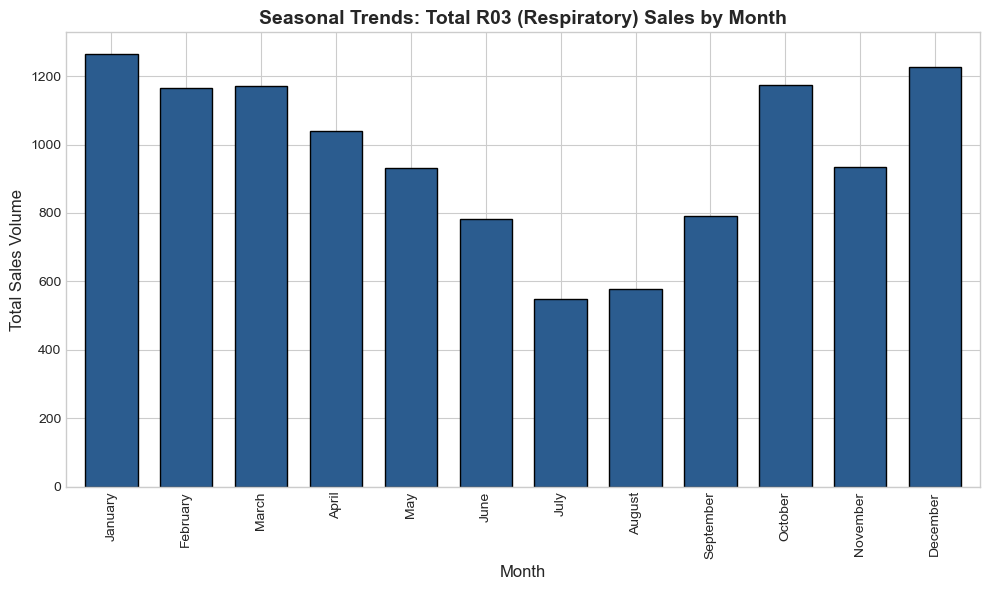

In [20]:
import matplotlib.pyplot as plt

# 1. Create figure
plt.figure(figsize=(10, 6))

# 2. Plot the data (THIS PLOTS THE BARS)
r03_monthly_sales.plot(kind='bar', color='#2b5c8f', edgecolor='black', width=0.7)

# 3. Add titles and labels
plt.title('Seasonal Trends: Total R03 (Respiratory) Sales by Month', fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Total Sales Volume', fontsize=12)

# 4. Display chart
plt.tight_layout()
plt.show()